# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">
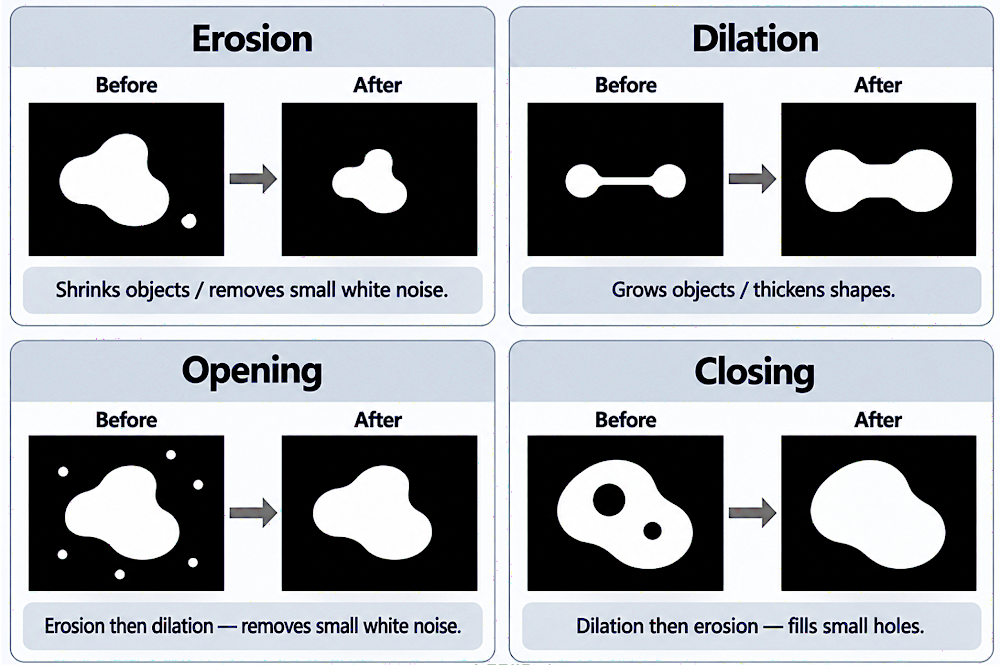


| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [79]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

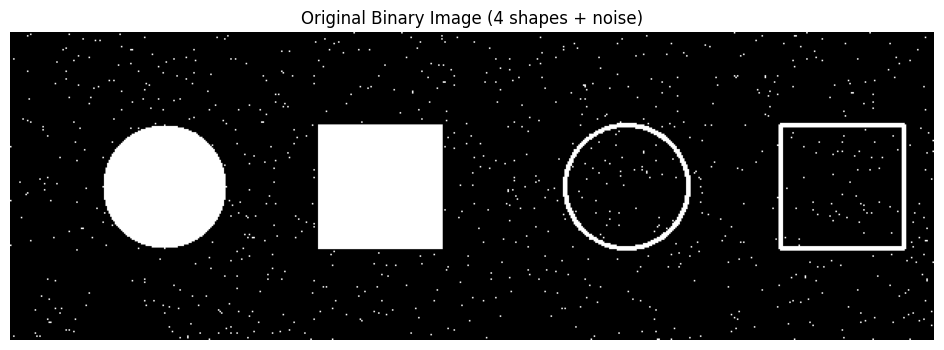

In [80]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8) # Zeros means black
cv2.circle(image, (100, 100), 40, 255, -1) # Solid circle (filled) - radius=40 | 255 means white
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)  # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2) # Hollow circle (outline) (100, 100) is the center of the circle 
cv2.rectangle(image, (500, 60), (580, 140), 255, 2) # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0) # each run gives the same output
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255 # white noise

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [81]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



In [82]:
Eimg=cv2.erode(image, kernel, iterations=1) # terations=1 do th erotion 1 time only
Dimg=cv2.dilate(image, kernel, iterations=1)
Oimg=cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
Cimg=cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

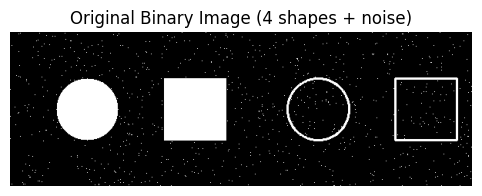

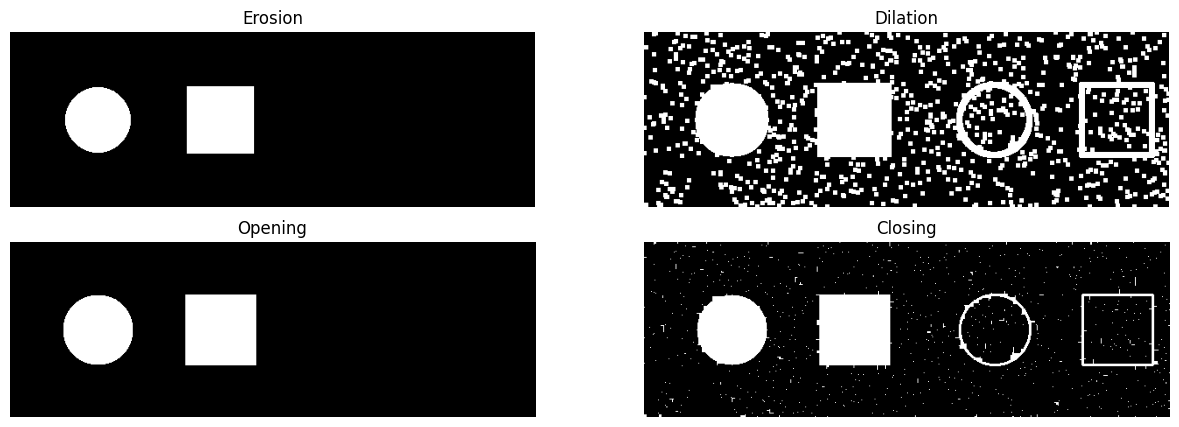

In [83]:
plt.figure(figsize=(8, 2))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(15, 5))
ax[0][0].imshow(Eimg, cmap='gray');  ax[0][0].set_title("Erosion");  ax[0][0].axis("off")
ax[0][1].imshow(Dimg, cmap='gray');    ax[0][1].set_title("Dilation");   ax[0][1].axis("off")
ax[1][0].imshow(Oimg,cmap='gray');      ax[1][0].set_title("Opening");              ax[1][0].axis("off")
ax[1][1].imshow(Cimg,cmap='gray');    ax[1][1].set_title("Closing");               ax[1][1].axis("off")
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

In [84]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)



In [85]:
cEimg=cv2.erode(image, circle_kernel, iterations=1) # terations=1 do th erotion 1 time only
cDimg=cv2.dilate(image, circle_kernel, iterations=1)
cOimg=cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
cCimg=cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

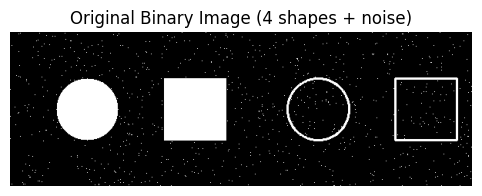

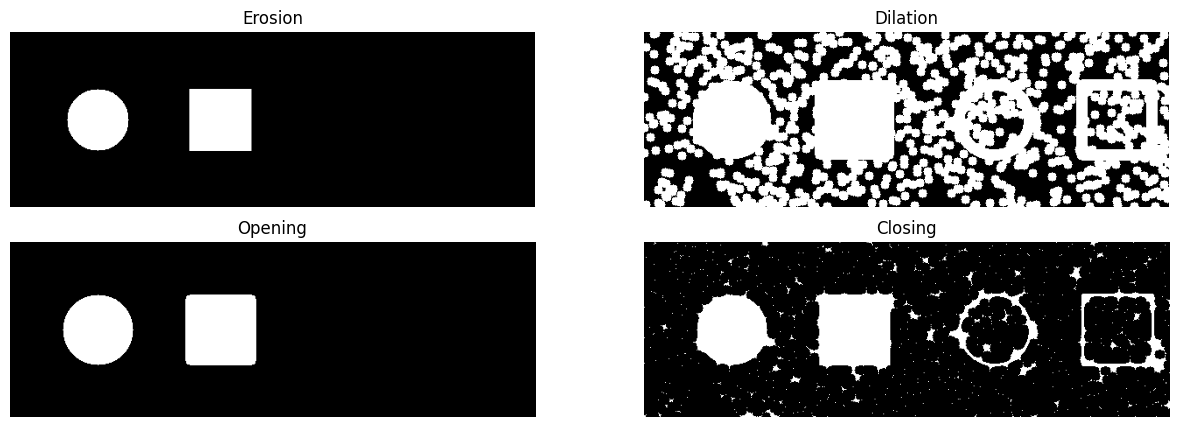

In [86]:
plt.figure(figsize=(8, 2))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()
fig, ax = plt.subplots(2, 2, figsize=(15, 5))
ax[0][0].imshow(cEimg,cmap='gray');  ax[0][0].set_title("Erosion");  ax[0][0].axis("off")
ax[0][1].imshow(cDimg,cmap='gray');    ax[0][1].set_title("Dilation");   ax[0][1].axis("off")
ax[1][0].imshow(cOimg,cmap='gray');      ax[1][0].set_title("Opening");              ax[1][0].axis("off")
ax[1][1].imshow(cCimg,cmap='gray');    ax[1][1].set_title("Closing");               ax[1][1].axis("off")
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



A square kernel includes all pixels in a square block, so the result looks more blocky and heavily smoothed. A circular kernel only includes pixels within a radius, so the result looks smoother and more natural with less harsh edges.